In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yaml

In [7]:
config_path = "config.yaml"
title = "first try rwanda radar"

In [8]:
with open(config_path, 'r') as f:
    try:
        setup_params = yaml.safe_load(f)
        # print(setup_params)
    except yaml.YAMLError as exc:
        print(exc)
        
logs_folder = setup_params["SETUP"]["log_folder"]

Skipping line 25: Expected 12 fields in line 25, saw 15. Error could possibly be due to quotes being ignored when a multi-char delimiter is used.


,N,CRPS,CRPS_max_4,CRPS_max_16,CRPS_avg_4,CRPS_avg_16,RMSE,EMRMSE,RALSD,MAE,OPL,OPR
0,16,4.610422,6.693933,16.811155,4.825767,5.953812,12.894507,10.612134,41.049622,6.806243,0.999656,0.000004
1,32,3.293362,4.703858,11.635298,3.429911,4.171854,8.724714,7.095959,37.664861,4.797458,0.999458,0.000015
2,48,2.470739,3.470978,8.305563,2.560692,3.071570,6.066498,4.938277,34.555091,3.547456,0.999275,0.000013
3,64,1.927354,2.674569,6.178476,1.990609,2.361029,4.392996,3.617292,31.410043,2.733976,0.999079,0.000025
4,80,1.558052,2.145091,4.845919,1.604370,1.887536,3.387717,2.811166,28.962364,2.196887,0.998725,0.000070


  Lowest CRPS = 0.092880 at N = 256


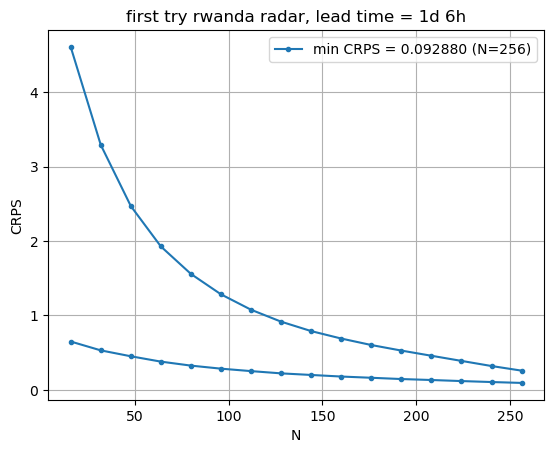

In [9]:
file_name = f"{logs_folder}/eval_validation.txt"
df = pd.read_csv(
    file_name,
    sep=r"\s+",
    header=3,
    # nrows=500,
    engine="python",
    on_bad_lines="warn",
)

display(df.head())

df["CRPS"] = pd.to_numeric(df["CRPS"], errors="coerce")
df["N"] = pd.to_numeric(df["N"], errors="coerce")

min_idx = df["CRPS"].idxmin()
min_crps = df.loc[min_idx, "CRPS"]
best_N = int(df.loc[min_idx, "N"])

print(f"  Lowest CRPS = {min_crps:.6f} at N = {best_N}")

plt.plot(df["N"], df["CRPS"], '.-',
        label=f"min CRPS = {min_crps:.6f} (N={best_N})")

plt.grid()
plt.xlabel("N")
plt.ylabel("CRPS")
plt.title(f"{title}, lead time = 1d 6h")
plt.legend()
plt.show()